In [46]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd

# Caracterização

In [ ]:

# =========================
# GLOBAL CONSTANTS
# =========================

DAY_MINUTES = 24 * 60
T = DAY_MINUTES

T_NO_ACTIVITY_FALLBACK = 1000
T_OFF_FORCED_ON = 5

ZONE_LIMITS = {
    0: (0, 600),       # 00:00 - 09:59
    1: (600, 1170),   # 10:00 - 19:29
    2: (1170, 1350),  # 19:30 - 22:29
    3: (1350, 1440),  # 22:30 - 23:59
}

BUFFERED_DEVICES = {0, 2}        # Drinks Refrigerator, Garde Manger
OPERATIONAL_DEVICES = {1, 3, 4, 5, 6}  # Blast Chiller, Ice Machine, Dual Fryer, Salamander, Infrared Shelf
NON_FLEXIBLE_DEVICES = {7, 8, 9}  # Glass Washer, Dish Washer, Convection Oven

N_DEV=10

diretorio = "/Users/luismartins/Desktop/Tese/Tese_repository/Data/"

activation_files = {
    0: "activations_Drinks_Refrigerator.csv",
    1: "activations_Blast_Chiller.csv",
    2: "activations_Garde_Manger_10.csv",
    3: "activations_Ice_Machine.csv",
    4: "activations_Dual_Fryer.csv",
    5: "activations_Salamander_1.csv",
    6: "activations_Infrared_Shelf.csv",
    7: "activations_Glass_Washer.csv",
    8: "activations_Dish_Washer_Original.csv",
    9: "activations_Convection_Oven_1.csv",
}

device_names = {
    0: "Drinks Refrigerator",
    1: "Blast Chiller",
    2: "Garde Manger",
    3: "Ice Machine",
    4: "Dual Fryer",
    5: "Salamander",
    6: "Infrared Shelf",
    7: "Glass Washer",
    8: "Dish Washer",
    9: "Convection Oven",
}

train_dates = pd.date_range(
    start="2019-02-13",
    end="2019-02-20",
    freq="D"
).date

In [49]:
# ======================================
# LEITURA DO INFO.XLSX
# ======================================

df_info = pd.read_excel('/Users/luismartins/Desktop/Tese/Tese_repository/Code/Multiple_Day_Methodology/Info_MD.xlsx')

print("Colunas do Info.xlsx:")
print(df_info.columns.tolist())

# se quiseres confirmar o número de equipamentos do Excel
print("\nNúmero de linhas no Info.xlsx:", len(df_info))

# opcional: garantir consistência
if len(df_info) != N_DEV:
    raise ValueError(f"N_DEV={N_DEV}, mas o Info.xlsx tem {len(df_info)} linhas.")

# parâmetros por equipamento
dev_names = df_info["Dev"].tolist()

# índice do tipo de flexibilidade
Type = df_info["Type"].to_numpy(dtype=int)

# estado inicial
# para já vamos ler do Excel; mais tarde podes forçar a zero ou atualizar dinamicamente
State_Init = df_info["State_Init"].to_numpy(dtype=int)

# potência máxima
Power_max = df_info["Power_max"].to_numpy(dtype=float)

# pesos da componente de potência
Weight_P_max = df_info["Weight_P_max"].to_numpy(dtype=float)
Weight_P_min = df_info["Weight_P_min"].to_numpy(dtype=float)

# percentagens de potência
# MUITO IMPORTANTE: converter de % para fração
Y_max = df_info["Y_max (%)"].to_numpy(dtype=float) / 100.0
Y_min = df_info["Y_min (%)"].to_numpy(dtype=float) / 100.0

# tempo mínimo para manter alteração de potência
TimeHoldPower = df_info["TimeHoldPower"].to_numpy(dtype=float)

# impressão de controlo
print("\nResumo dos equipamentos:")
for j in range(N_DEV):
    print(
        f"{j}: {dev_names[j]} | "
        f"Type={Type[j]} | "
        f"State_Init={State_Init[j]} | "
        f"Pmax={Power_max[j]} | "
        f"Ymin={Y_min[j]} | "
        f"Ymax={Y_max[j]}"
        f" | TimeHoldPower={TimeHoldPower[j]}"
    )

Colunas do Info.xlsx:
['Dev', 'j', 'Type', 'State_Init', 'Power_max', 'Weight_P_max', 'Weight_P_min', 'Y_max (%)', 'Y_min (%)', 'TimeHoldPower']

Número de linhas no Info.xlsx: 10

Resumo dos equipamentos:
0: Drinks Refrigerator | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
1: Blast Chiller | Type=2 | State_Init=0 | Pmax=1500.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
2: Garde Manger | Type=2 | State_Init=0 | Pmax=1000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
3: Ice Machine | Type=2 | State_Init=0 | Pmax=400.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
4: Dual Fryer | Type=2 | State_Init=0 | Pmax=5000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
5: Salamander | Type=2 | State_Init=0 | Pmax=3000.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
6: Infrared Shelf | Type=2 | State_Init=0 | Pmax=800.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
7: Glass Washer | Type=0 | State_Init=0 | Pmax=1600.0 | Ymin=1.0 | Ymax=1.0 | TimeHoldPower=-1.0
8: Dish Washer 

### Helper Functions - get X (Multiple day)

In [50]:
def minute_of_day(ts):
    m = ts.hour * 60 + ts.minute
    if ts.second >= 30:
        m += 1
    return min(m, 1439)


def get_time_zone(minute):
    if 0 <= minute <= 599:
        return 0
    elif 600 <= minute <= 1169:
        return 1
    elif 1170 <= minute <= 1349:
        return 2
    else:
        return 3


def load_activation_csv_full_dataset(diretorio, nome_do_arquivo):
    caminho_arquivo = os.path.join(diretorio, nome_do_arquivo)

    if not os.path.exists(caminho_arquivo):
        print(f"[WARNING] File not found: {caminho_arquivo}")
        return pd.DataFrame(columns=["first_min_on", "last_min_on"])

    try:
        df = pd.read_csv(caminho_arquivo, sep=";").iloc[:, 0:3].copy()
    except Exception as e:
        print(f"[WARNING] Could not read file {caminho_arquivo}: {e}")
        return pd.DataFrame(columns=["first_min_on", "last_min_on"])

    df.columns = df.columns.str.strip()

    if "first_min_on" not in df.columns or "last_min_on" not in df.columns:
        print(f"[WARNING] Missing required columns in {caminho_arquivo}")
        return pd.DataFrame(columns=["first_min_on", "last_min_on"])

    df["first_min_on"] = pd.to_datetime(
        df["first_min_on"],
        utc=True,
        errors="coerce"
    )

    df["last_min_on"] = pd.to_datetime(
        df["last_min_on"],
        utc=True,
        errors="coerce"
    )

    df["first_min_on"] = df["first_min_on"].dt.tz_convert(None)
    df["last_min_on"] = df["last_min_on"].dt.tz_convert(None)

    df = df.dropna(subset=["first_min_on", "last_min_on"])
    df = df[df["last_min_on"] >= df["first_min_on"]].copy()

    df = df.sort_values("first_min_on").reset_index(drop=True)

    return df

def build_X_day_for_device_from_df(df_device, target_date):
    """
    Constrói vetor X diário para um device.
    Se não houver dados nesse dia, devolve tudo a zero.
    """
    x = np.zeros(DAY_MINUTES, dtype=int)

    if df_device is None or df_device.empty:
        return x

    target_date = pd.to_datetime(target_date).date()

    df_day = df_device[
        df_device["first_min_on"].dt.date == target_date
    ].copy()

    if df_day.empty:
        return x

    for _, row in df_day.iterrows():
        start = minute_of_day(row["first_min_on"])
        end = minute_of_day(row["last_min_on"])

        if end >= start:
            x[start:end + 1] = 1
        else:
            x[start:DAY_MINUTES] = 1
            x[0:end + 1] = 1

    return x

def build_X_days_matrix(
    dates,
    activation_files,
    diretorio,
    n_dev,
    verbose=True
):
    """
    Retorna:
        X_days_matrix[day_idx, minute, device]

    Shape:
        (n_days, 1440, n_dev)

    Se faltar algum ficheiro ou algum dia não tiver dados,
    os valores permanecem a zero.
    """
    dates = [pd.to_datetime(d).date() for d in dates]

    X_days_matrix = np.zeros(
        (len(dates), DAY_MINUTES, n_dev),
        dtype=int
    )

    loaded_data = {}

    for j, filename in activation_files.items():
        df_j = load_activation_csv_full_dataset(
            diretorio=diretorio,
            nome_do_arquivo=filename
        )

        loaded_data[j] = df_j

        if verbose:
            print(
                f"Device {j}: {filename} | "
                f"{len(df_j)} activations loaded"
            )

    for d_idx, target_date in enumerate(dates):
        if verbose:
            print(f"\nBuilding X for day {target_date}")

        for j, df_device in loaded_data.items():
            X_days_matrix[d_idx, :, j] = build_X_day_for_device_from_df(
                df_device=df_device,
                target_date=target_date
            )

            if verbose:
                on_minutes = int(X_days_matrix[d_idx, :, j].sum())
                print(
                    f"  Device {j}: "
                    f"{on_minutes} ON minutes"
                )

    return X_days_matrix

In [ ]:
X_days_matrix = build_X_days_matrix(
    dates=train_dates,
    activation_files=activation_files,
    diretorio=diretorio,
    n_dev=N_DEV,
    verbose=True
)

Device 0: activations_Drinks_Refrigerator.csv | 230 activations loaded
Device 1: activations_Blast_Chiller.csv | 235 activations loaded
Device 2: activations_Garde_Manger_10.csv | 764 activations loaded
Device 3: activations_Ice_Machine.csv | 1461 activations loaded
Device 4: activations_Dual_Fryer.csv | 1077 activations loaded
Device 5: activations_Salamander_1.csv | 22 activations loaded
Device 6: activations_Infrared_Shelf.csv | 39 activations loaded
Device 7: activations_Glass_Washer.csv | 486 activations loaded
Device 8: activations_Dish_Washer_Original.csv | 1690 activations loaded
Device 9: activations_Convection_Oven_1.csv | 182 activations loaded

Building X for day 2019-02-13
  Device 0: 259 ON minutes
  Device 1: 467 ON minutes
  Device 2: 114 ON minutes
  Device 3: 608 ON minutes
  Device 4: 133 ON minutes
  Device 5: 492 ON minutes
  Device 6: 499 ON minutes
  Device 7: 364 ON minutes
  Device 8: 252 ON minutes
  Device 9: 205 ON minutes

Building X for day 2019-02-14
  De

### Get T_ON and T_OFF

In [52]:
def get_blocks_from_binary_vector(x):
    """
    Returns consecutive ON and OFF block durations.
    """
    on_blocks = []
    off_blocks = []

    if len(x) == 0:
        return on_blocks, off_blocks

    current_state = x[0]
    count = 1

    for val in x[1:]:
        if val == current_state:
            count += 1
        else:
            if current_state == 1:
                on_blocks.append(count)
            else:
                off_blocks.append(count)

            current_state = val
            count = 1

    if current_state == 1:
        on_blocks.append(count)
    else:
        off_blocks.append(count)

    return on_blocks, off_blocks

In [53]:
def characterize_device_multiday_by_timezone(
    X_days_matrix,
    device_idx
):
    """
    Calculates T_ON and T_OFF for one device.

    Logic:
    - for each day
    - for each timezone
    - calculate median ON/OFF block duration
    - then aggregate across days using median
    """

    records = []

    n_days = X_days_matrix.shape[0]

    for day_idx in range(n_days):

        x_day = X_days_matrix[day_idx, :, device_idx]

        for z, (start_z, end_z) in ZONE_LIMITS.items():

            x_zone = x_day[start_z:end_z]
            on_minutes = int(np.sum(x_zone))

            if on_minutes == 0:
                ton_day = T_NO_ACTIVITY_FALLBACK
                toff_day = T_NO_ACTIVITY_FALLBACK

            else:
                on_blocks, off_blocks = get_blocks_from_binary_vector(x_zone)

                if len(on_blocks) > 0:
                    ton_day = max(1, int(np.median(on_blocks)))
                else:
                    ton_day = T_NO_ACTIVITY_FALLBACK

                valid_off_blocks = [b for b in off_blocks if b > 0]

                if len(valid_off_blocks) > 0:
                    toff_day = max(1, int(np.median(valid_off_blocks)))
                else:
                    toff_day = T_OFF_FORCED_ON

            records.append({
                "day_idx": day_idx,
                "device": device_idx,
                "time_zone": z,
                "T_ON_day": ton_day,
                "T_OFF_day": toff_day,
                "on_minutes": on_minutes
            })

    df_daily = pd.DataFrame(records)

    df_summary = (
        df_daily
        .groupby(["device", "time_zone"])
        .agg(
            T_ON=("T_ON_day", "median"),
            T_OFF=("T_OFF_day", "median"),
            n_days=("day_idx", "nunique"),
            on_minutes_median=("on_minutes", "median")
        )
        .reset_index()
    )

    df_summary["T_ON"] = df_summary["T_ON"].astype(int)
    df_summary["T_OFF"] = df_summary["T_OFF"].astype(int)

    return df_daily, df_summary

all_daily_records = []
all_summary_records = []

for j in sorted(BUFFERED_DEVICES.union(OPERATIONAL_DEVICES)):

    df_daily_j, df_summary_j = characterize_device_multiday_by_timezone(
        X_days_matrix=X_days_matrix,
        device_idx=j
    )

    all_daily_records.append(df_daily_j)
    all_summary_records.append(df_summary_j)

df_daily_characterization = pd.concat(
    all_daily_records,
    ignore_index=True
)

df_timezone_summary = pd.concat(
    all_summary_records,
    ignore_index=True
)

def build_ton_toff_matrices_from_summary(
    df_summary,
    n_dev
):
    T_ON_matrix = np.ones((DAY_MINUTES, n_dev), dtype=int)
    T_OFF_matrix = np.ones((DAY_MINUTES, n_dev), dtype=int)

    for _, row in df_summary.iterrows():

        j = int(row["device"])
        z = int(row["time_zone"])

        start_z, end_z = ZONE_LIMITS[z]

        T_ON_matrix[start_z:end_z, j] = int(row["T_ON"])
        T_OFF_matrix[start_z:end_z, j] = int(row["T_OFF"])

    return T_ON_matrix, T_OFF_matrix

T_ON_FC_matrix, T_OFF_FC_matrix = build_ton_toff_matrices_from_summary(
    df_summary=df_timezone_summary,
    n_dev=N_DEV
)

In [61]:
def characterize_device_multiday_by_hour(
    X_days_matrix,
    device_idx
):
    """
    Calculates T_ON and T_OFF for one device.

    Logic:
    - for each day
    - for each hour
    - calculate median ON/OFF block duration inside that hour
    - then aggregate across days using median

    Fallbacks:
    - no ON minutes in hour:
        T_ON  = T_NO_ACTIVITY_FALLBACK
        T_OFF = T_NO_ACTIVITY_FALLBACK

    - ON minutes exist but no OFF block:
        T_OFF = T_OFF_FORCED_ON
    """

    records = []

    n_days = X_days_matrix.shape[0]

    for day_idx in range(n_days):

        x_day = X_days_matrix[day_idx, :, device_idx]

        for h in range(24):

            start_h = h * 60
            end_h = (h + 1) * 60

            x_hour = x_day[start_h:end_h]
            on_minutes = int(np.sum(x_hour))

            if on_minutes == 0:
                ton_day = T_NO_ACTIVITY_FALLBACK
                toff_day = T_NO_ACTIVITY_FALLBACK

            else:
                on_blocks, off_blocks = get_blocks_from_binary_vector(x_hour)

                if len(on_blocks) > 0:
                    ton_day = max(1, int(np.median(on_blocks)))
                else:
                    ton_day = T_NO_ACTIVITY_FALLBACK

                valid_off_blocks = [b for b in off_blocks if b > 0]

                if len(valid_off_blocks) > 0:
                    toff_day = max(1, int(np.median(valid_off_blocks)))
                else:
                    toff_day = T_OFF_FORCED_ON

            records.append({
                "day_idx": day_idx,
                "device": device_idx,
                "hour": h,
                "T_ON_day": ton_day,
                "T_OFF_day": toff_day,
                "on_minutes": on_minutes
            })

    df_daily = pd.DataFrame(records)

    df_summary = (
        df_daily
        .groupby(["device", "hour"])
        .agg(
            T_ON=("T_ON_day", "median"),
            T_OFF=("T_OFF_day", "median"),
            n_days=("day_idx", "nunique"),
            on_minutes_median=("on_minutes", "median")
        )
        .reset_index()
    )

    df_summary["T_ON"] = df_summary["T_ON"].astype(int)
    df_summary["T_OFF"] = df_summary["T_OFF"].astype(int)

    return df_daily, df_summary

def build_ton_toff_matrices_from_hour_summary(
    df_summary,
    n_dev
):
    T_ON_matrix = np.ones((DAY_MINUTES, n_dev), dtype=int)
    T_OFF_matrix = np.ones((DAY_MINUTES, n_dev), dtype=int)

    for _, row in df_summary.iterrows():

        j = int(row["device"])
        h = int(row["hour"])

        start_h = h * 60
        end_h = (h + 1) * 60

        T_ON_matrix[start_h:end_h, j] = int(row["T_ON"])
        T_OFF_matrix[start_h:end_h, j] = int(row["T_OFF"])

    return T_ON_matrix, T_OFF_matrix

all_daily_records = []
all_summary_records = []

for j in sorted(BUFFERED_DEVICES.union(OPERATIONAL_DEVICES)):

    df_daily_j, df_summary_j = characterize_device_multiday_by_hour(
        X_days_matrix=X_days_matrix,
        device_idx=j
    )

    all_daily_records.append(df_daily_j)
    all_summary_records.append(df_summary_j)

df_daily_characterization_hour = pd.concat(
    all_daily_records,
    ignore_index=True
)

df_hour_summary = pd.concat(
    all_summary_records,
    ignore_index=True
)

T_ON_FC_matrix, T_OFF_FC_matrix = build_ton_toff_matrices_from_hour_summary(
    df_summary=df_hour_summary,
    n_dev=N_DEV
)

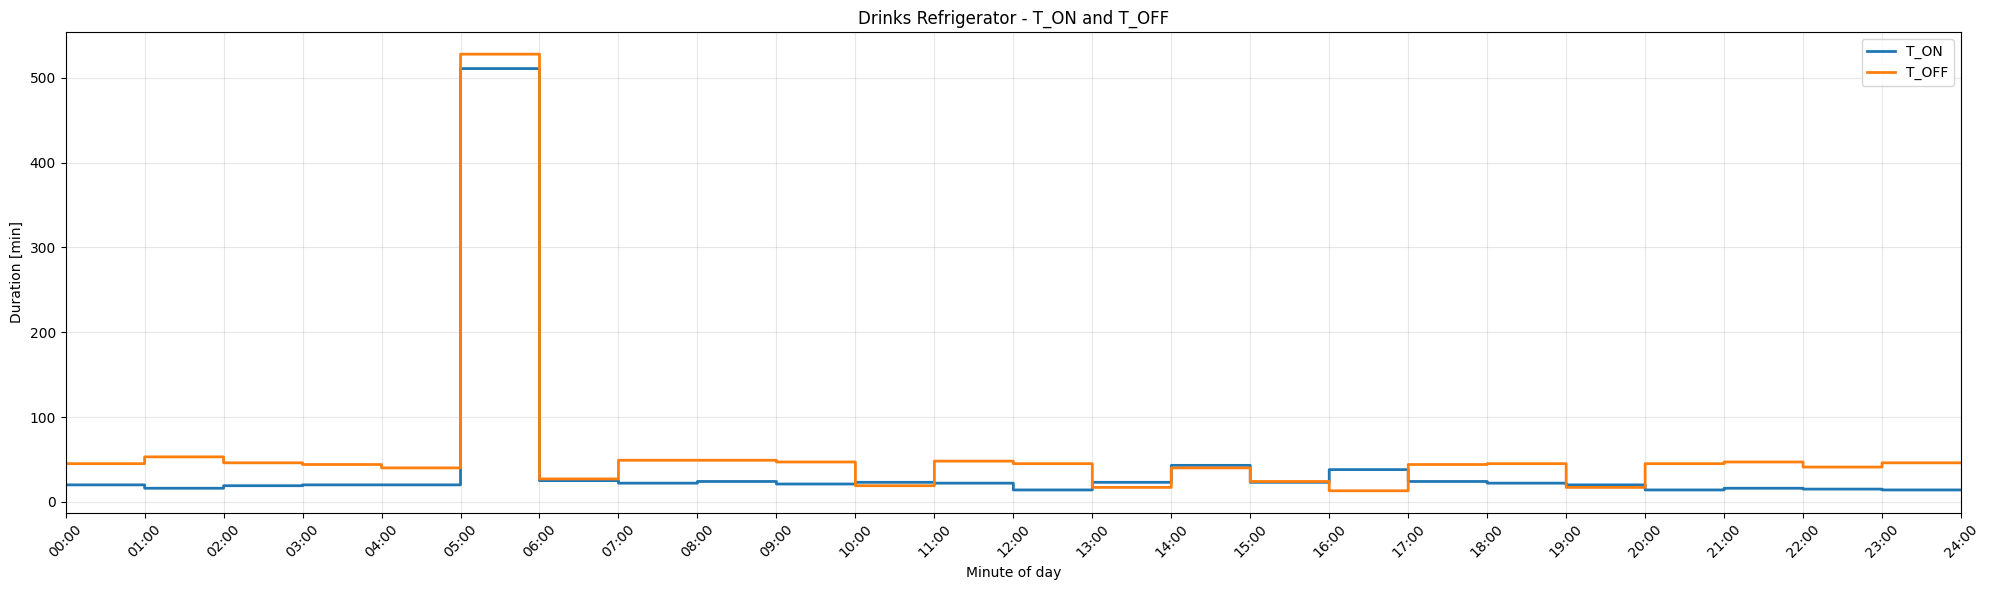

In [62]:
def plot_ton_toff_day(
    device_idx,
    T_ON_matrix,
    T_OFF_matrix,
    device_names=None,
    title_suffix=""
):
    minutes = np.arange(DAY_MINUTES)

    device_name = (
        device_names.get(device_idx, f"Device {device_idx}")
        if device_names is not None
        else f"Device {device_idx}"
    )

    plt.figure(figsize=(20, 6))

    plt.step(
        minutes,
        T_ON_matrix[:, device_idx],
        where="post",
        linewidth=2,
        label="T_ON"
    )

    plt.step(
        minutes,
        T_OFF_matrix[:, device_idx],
        where="post",
        linewidth=2,
        label="T_OFF"
    )

    plt.title(f"{device_name} - T_ON and T_OFF{title_suffix}")
    plt.xlabel("Minute of day")
    plt.ylabel("Duration [min]")

    plt.xlim(0, DAY_MINUTES)

    plt.xticks(
        np.arange(0, DAY_MINUTES + 1, 60),
        [f"{h:02d}:00" for h in range(25)],
        rotation=45
    )

    plt.grid(True, alpha=0.3)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

plot_ton_toff_day(
    device_idx=0,
    T_ON_matrix=T_ON_FC_matrix,
    T_OFF_matrix=T_OFF_FC_matrix,
    device_names=device_names
)

In [63]:

def build_power_day_device(X_day_j, P_max_j):
    return X_day_j * P_max_j

def plot_power_weight_day(device_idx, X_day_matrix, W_matrix, P_max, device_names):
    minutes = np.arange(DAY_MINUTES)

    power = X_day_matrix[:, device_idx] * P_max[device_idx]
    W = W_matrix[:, device_idx]

    fig, ax1 = plt.subplots(figsize=(20, 6))

    ax1.bar(minutes, power, alpha=0.45, width=1.0, label="Power")
    ax1.set_ylabel("Power [W]", fontsize=16, fontweight="bold")
    ax1.set_xlabel("Time", fontsize=16, fontweight="bold")
    ax1.set_xlim(0, DAY_MINUTES)
    ax1.set_ylim(0, P_max[device_idx] * 1.2)

    ax2 = ax1.twinx()
    ax2.plot(minutes, W, linewidth=3, label=r"$W_{baseline}$")
    ax2.set_ylabel(r"$W_{baseline}$", fontsize=16, fontweight="bold")
    ax2.set_ylim(0, 12)

    ticks = np.arange(0, DAY_MINUTES + 1, 60)
    ax1.set_xticks(ticks)
    ax1.set_xticklabels([f"{m//60:02d}:{m%60:02d}" for m in ticks], rotation=90)

    ax1.grid(True, alpha=0.3)

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.28),
        ncol=2,
        fontsize=14
    )

    plt.title(f"{device_names[device_idx]} - Power and baseline weight", fontsize=16)
    plt.tight_layout()
    plt.show()

In [64]:
def get_w_max(j, minute, variable_hysteresis=False):

    return 10.0

def update_weights_and_flags(
    prev_W,
    X_now,
    Type,
    T_ON_now,
    T_OFF_now,
    minute,
    variable_hysteresis=False
):
    n = len(X_now)
    W_new = np.zeros(n, dtype=float)
    force_on_flag = np.zeros(n, dtype=int)

    for j in range(n):

        if Type[j] != 2:
            W_new[j] = 10.0
            force_on_flag[j] = 0
            continue

        W_max_now = get_w_max(j, minute, variable_hysteresis)

        if X_now[j] == 1:
            raw_w = prev_W[j] - 9.0 / max(T_ON_now[j], 1)
            W_new[j] = max(1.0, raw_w)
            force_on_flag[j] = 0

        else:
            raw_w = prev_W[j] + 9.0 / max(T_OFF_now[j], 1)

            if raw_w >= W_max_now:
                W_new[j] = W_max_now
                force_on_flag[j] = 1
            else:
                W_new[j] = raw_w
                force_on_flag[j] = 0

    return np.round(W_new, 3), force_on_flag

def compute_W_baseline_matrix(X_day_matrix, T_ON_matrix, T_OFF_matrix, Type):
    n_dev = X_day_matrix.shape[1]

    W = np.zeros((DAY_MINUTES, n_dev))
    flags = np.zeros((DAY_MINUTES, n_dev), dtype=int)

    for j in range(n_dev):
        W[0, j] = 10.0 if (Type[j] != 2 or X_day_matrix[0, j] == 1) else 1.0

    for t in range(1, DAY_MINUTES):
        W[t, :], flags[t, :] = update_weights_and_flags(
            prev_W=W[t - 1, :],
            X_now=X_day_matrix[t, :],
            Type=Type,
            T_ON_now=T_ON_matrix[t, :],
            T_OFF_now=T_OFF_matrix[t, :],
            minute=t
        )

    return W, flags

def plot_power_weight_day(
    device_idx,
    X_day_matrix,
    W_matrix,
    Power_max,
    dev_names,
    tz_start=0,
    tz_end=24*60,
    tick_step=60,
    save_path=None
):
    import numpy as np
    import matplotlib.pyplot as plt

    minutes = np.arange(tz_start, tz_end)
    labels = [f"{m//60:02d}:{m%60:02d}" for m in minutes]
    x = np.arange(len(minutes))

    W = W_matrix[tz_start:tz_end, device_idx]
    P = X_day_matrix[tz_start:tz_end, device_idx] * Power_max[device_idx]

    fig, ax1 = plt.subplots(figsize=(18, 6))

    ax1.fill_between(
        x,
        P,
        step="mid",
        color="#4F81BD",
        alpha=0.55,
        label="Power"
    )

    ax1.set_xlabel("Time", fontsize=18, fontweight="bold")
    ax1.set_ylabel("Power [W]", fontsize=18, fontweight="bold", color="black")

    p_max_plot = max(Power_max[device_idx], np.max(P))
    ax1.set_ylim(0, p_max_plot * 1.2)

    ax1.tick_params(axis="y", labelcolor="black")

    ax2 = ax1.twinx()

    ax2.plot(
        x,
        W,
        color="#9BBB59",
        linewidth=4,
        label=r"$W_{baseline}$"
    )

    ax2.set_ylabel(r"$W_{baseline}$", fontsize=18, fontweight="bold", color="black")
    ax2.set_ylim(0, 12)
    ax2.tick_params(axis="y", labelcolor="black")

    ax1.set_xticks(np.arange(0, len(labels), tick_step))
    ax1.set_xticklabels(labels[::tick_step], rotation=90, fontsize=11)

    ax1.grid(axis="y", alpha=0.3)

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2,
        frameon=False,
        fontsize=15
    )

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

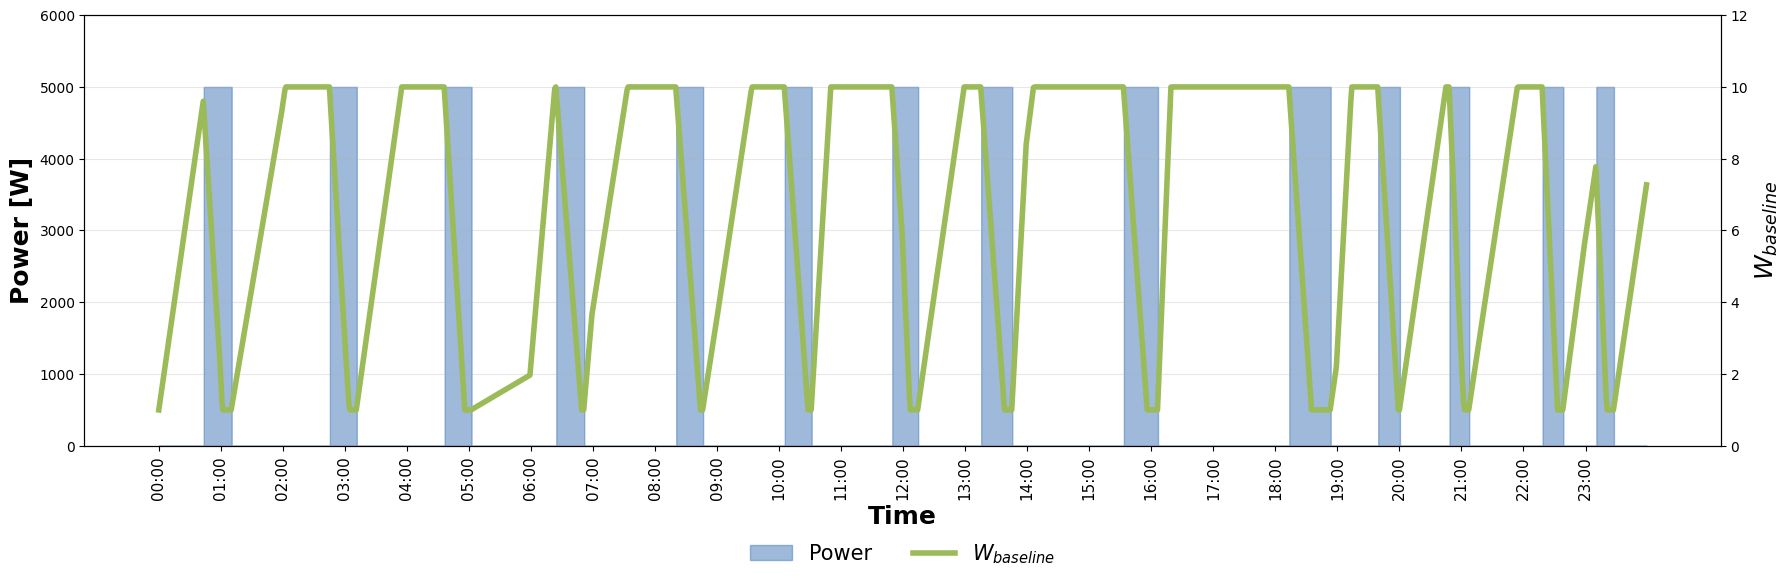

In [65]:
j = 0
test_date = pd.to_datetime("2019-02-14").date()

X_test = build_X_days_matrix(
    dates=[test_date],
    activation_files=activation_files,
    diretorio=diretorio,
    n_dev=N_DEV,
    verbose=False
)[0]

W_baseline, force_on_flags = compute_W_baseline_matrix(
    X_day_matrix=X_test,
    T_ON_matrix=T_ON_FC_matrix,
    T_OFF_matrix=T_OFF_FC_matrix,
    Type=Type
)
plot_power_weight_day(
    device_idx=0,
    X_day_matrix=X_test,
    W_matrix=W_baseline,
    Power_max=Power_max,
    dev_names=dev_names,
    tz_start=0,
    tz_end=24*60,
    tick_step=60,
    save_path=None
)